In [1]:
# CELL 1: imports
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedGroupKFold, LeaveOneGroupOut, cross_val_predict, cross_validate
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             precision_score, recall_score, fbeta_score)
sns.set_theme(style="whitegrid")

In [2]:
RED, GREEN, BLUE, AMBER = "#B23B32", "#3F8B5D", "#3D5A99", "#B9821E"   # red = spoiled, green = safe, blue = info, amber = caution
FIG_DIR = "../outputs/figures"      # BREAKS IF: this folder doesn't exist, so create it first
sns.set_theme(style="whitegrid")

In [4]:
# CELL 2: load and build BatchID (a batch = same product, stock, arrival and expiry)
dataset = pd.read_csv("../data/processed/smart_waste_features.csv", parse_dates=["ArrivalDate", "ExpiryDate"])
dataset["BatchID"] = (dataset["ItemName"] + "|" + dataset["StockQty"].astype(str) + "|" +
                      dataset["ArrivalDate"].dt.strftime("%m%d") + "|" + dataset["ExpiryDate"].dt.strftime("%m%d"))
print("rows:", len(dataset), "| unique batches:", dataset["BatchID"].nunique())          # 1000 | 50
print("batches whose rows disagree on IsSpoiled:", (dataset.groupby("BatchID")["IsSpoiled"].nunique() > 1).sum())   # 0
batches = (dataset.groupby("BatchID")
           .agg(arrival=("ArrivalDate", "min"), spoiled=("IsSpoiled", "first"), rows=("IsSpoiled", "size"))
           .sort_values("arrival"))
print("spoiled batches:", int(batches["spoiled"].sum()), "of", len(batches))             # 22 of 50

rows: 1000 | unique batches: 50
batches whose rows disagree on IsSpoiled: 0
spoiled batches: 22 of 50


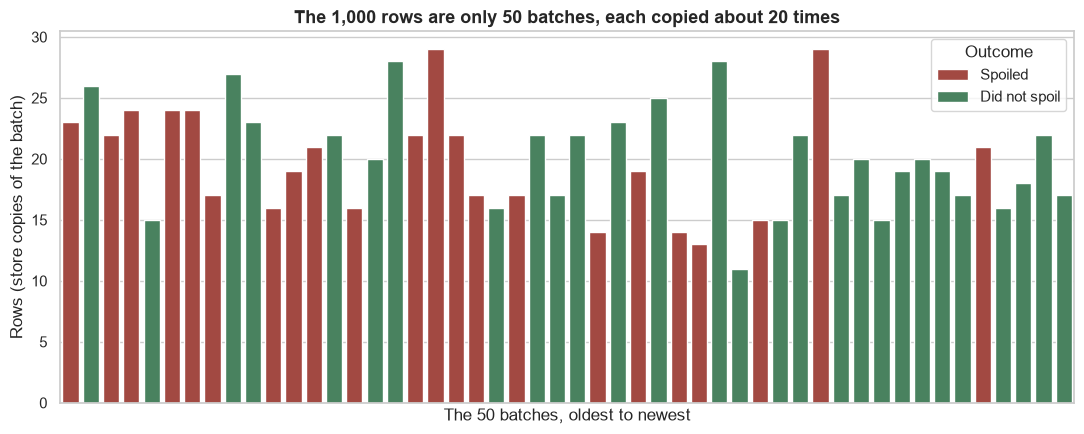

In [5]:
# One bar per batch: its height is how many store copies it has, its colour is its outcome.
b = batches.reset_index()
b["Outcome"] = b["spoiled"].map({True: "Spoiled", False: "Did not spoil"})
plt.figure(figsize=(11, 4.5))
sns.barplot(data=b, x=b.index, y="rows", hue="Outcome", palette={"Spoiled": RED, "Did not spoil": GREEN}, dodge=False)
plt.xticks([]); plt.xlabel("The 50 batches, oldest to newest"); plt.ylabel("Rows (store copies of the batch)")
plt.title(f"The {len(dataset):,} rows are only {len(b)} batches, each copied about {b['rows'].mean():.0f} times", fontsize=13, weight="bold")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/v1_batches.png", dpi=150)   # BREAKS IF: savefig comes after plt.show()
plt.show()

In [9]:
# Compares how many items spoiled in the rows the model learned from vs the rows it was tested on.
rates = pd.DataFrame({"Set": [f"Train ({len(train_ds)} rows)", f"Test ({len(test_ds)} rows)"],
                      "SpoiledRate": [train_ds["IsSpoiled"].mean(), test_ds["IsSpoiled"].mean()]})
plt.figure(figsize=(7, 4.5))
ax = sns.barplot(data=rates, x="Set", y="SpoiledRate", hue="Set",
                 palette=[COLOR_NEUTRAL, COLOR_WARN], legend=False)
for i, v in enumerate(rates["SpoiledRate"]):
    ax.text(i, v + 0.01, f"{v:.0%}", ha="center", fontweight="bold")   # writes the % above each bar
plt.title("The test set is much 'safer' than the training set", fontsize=13, weight="bold")
plt.ylabel("Share of items that spoiled"); plt.xlabel("")
plt.ylim(0, rates["SpoiledRate"].max() + 0.1)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/model_1_train_vs_test.png", dpi=150)   # BREAKS IF: savefig comes after plt.show()
plt.show()

NameError: name 'train_ds' is not defined

#### 2. Feature split

In [7]:
# CELL 3: the label depends on the date the data was pulled
by_arrival = (dataset.groupby(dataset["ArrivalDate"].dt.date)
              .agg(rows=("IsSpoiled", "size"), spoiled_rate=("IsSpoiled", "mean"), avg_days_left=("DaysUntilExpiry", "mean"))
              .round(2))
print(by_arrival)   # early arrivals: ~0.5 days left, high spoilage; late arrivals: ~5 days left, low spoilage

             rows  spoiled_rate  avg_days_left
ArrivalDate                                   
2025-06-12     95          0.73           0.50
2025-06-13     15          0.00           0.50
2025-06-14     92          0.71           0.50
2025-06-15     79          0.71           0.50
2025-06-16    108          0.35           0.50
2025-06-18    101          0.84           0.69
2025-06-19     98          0.14           1.29
2025-06-20     44          0.43           0.50
2025-06-21     27          1.00           0.50
2025-06-22     39          0.00           5.28
2025-06-23     52          0.29           1.80
2025-06-24     46          0.63           5.23
2025-06-25     93          0.00           4.67
2025-06-26     94          0.22           5.54
2025-06-27     17          0.00           9.00


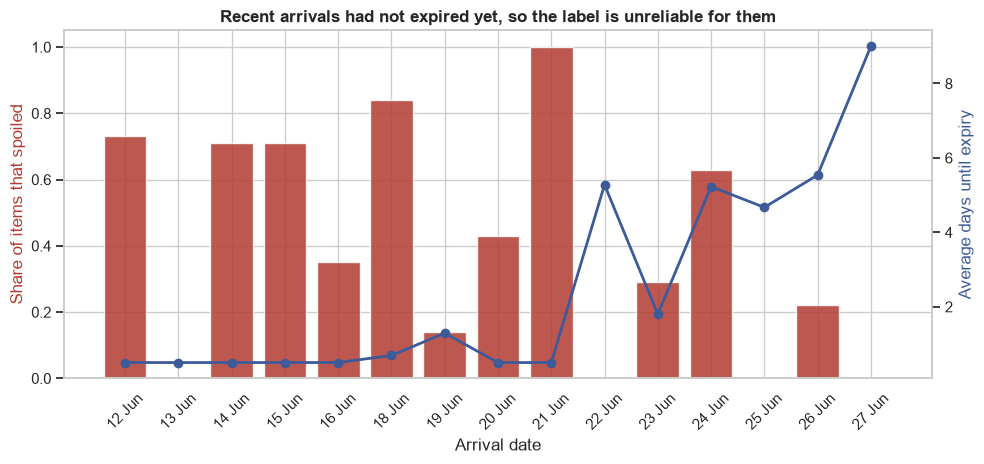

In [8]:
# Red bars = spoilage rate per arrival date; blue line = average days left until expiry.
fig, ax = plt.subplots(figsize=(10, 4.8))
labels = [d.strftime("%d %b") for d in by_arrival.index]
ax.bar(range(len(by_arrival)), by_arrival["spoiled_rate"].values, color=RED, alpha=0.85)
ax.set_xticks(range(len(by_arrival))); ax.set_xticklabels(labels, rotation=45)
ax.set_ylabel("Share of items that spoiled", color=RED); ax.set_xlabel("Arrival date")
ax2 = ax.twinx(); ax2.grid(False)                       # second y-axis so the two scales don't fight
ax2.plot(range(len(by_arrival)), by_arrival["avg_days_left"].values, color=BLUE, marker="o", linewidth=2)
ax2.set_ylabel("Average days until expiry", color=BLUE)
plt.title("Recent arrivals had not expired yet, so the label is unreliable for them", fontsize=12, weight="bold")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/v2_label_vs_date.png", dpi=150); plt.show()

In [11]:
# CELL 4: leakage audit - can the expiry-timing columns recover the label?
y_all, groups_all = dataset["IsSpoiled"], dataset["BatchID"]
def audit(columns, label):
    X = pd.get_dummies(dataset[columns])
    cv = StratifiedGroupKFold(5, shuffle=True, random_state=1)    # folds never split a batch
    pred = cross_val_predict(DecisionTreeClassifier(max_depth=4, random_state=0), X, y_all, cv=cv, groups=groups_all)
    return {"Features used": label, "Recall": round(recall_score(y_all, pred), 2), "Precision": round(precision_score(y_all, pred), 2)}

numeric_features = ["StockQty", "DailySaleAvg", "Days_To_Clear_Stock", "Sales_vs_Nearby_Gap",
                    "DistanceToNearestStore", "AvgDailySaleInNearbyStores"]
categorical_features = ["Category", "StoreLocation", "Zone", "TemperatureSupport", "OnPromotion", "TemperatureSensitive"]
features = numeric_features + categorical_features
print(pd.DataFrame([
    audit(["DaysUntilExpiry"], "DaysUntilExpiry alone"),
    audit(["Stock_Coverage_Ratio"], "Stock_Coverage_Ratio alone (uses DaysUntilExpiry)"),
    audit(["DaysUntilExpiry", "Days_In_Store_So_Far", "Total_Shelf_Life_Days"], "the three expiry-timing columns"),
    audit(features, "clean features (no expiry timing)"),
]))

                                       Features used  Recall  Precision
0                              DaysUntilExpiry alone    0.95       0.57
1  Stock_Coverage_Ratio alone (uses DaysUntilExpiry)    0.75       0.64
2                    the three expiry-timing columns    0.86       0.64
3                  clean features (no expiry timing)    0.39       0.40


In [12]:
# Recall of a small tree using each feature set; red = leaky, blue = clean.
plt.figure(figsize=(9, 4))
ax = sns.barplot(data=audit_table, x="Recall", y="Features used", hue="Features used",
                 palette=[RED, RED, RED, BLUE], legend=False, orient="h")   # BREAKS IF: palette length differs from the 4 rows
for i, v in enumerate(audit_table["Recall"]): ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontweight="bold")
plt.xlim(0, 1.1); plt.ylabel(""); plt.xlabel("Share of spoiled items caught (batch-grouped validation)")
plt.title("Expiry-timing columns give the answer away", fontsize=13, weight="bold")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/v3_leakage_audit.png", dpi=150); plt.show()

NameError: name 'audit_table' is not defined

<Figure size 900x400 with 0 Axes>

In [32]:
# CELL 5: split by whole batches (the last 10 batches by arrival date are the test set, used once)
N_TEST_BATCHES = 10
test_batches = set(batches.index[-N_TEST_BATCHES:])
test_ds = dataset[dataset["BatchID"].isin(test_batches)].copy()
dev_ds = dataset[~dataset["BatchID"].isin(test_batches)].copy()
print("dev :", dev_ds["BatchID"].nunique(), "batches,", len(dev_ds), "rows")
print("test:", test_ds["BatchID"].nunique(), "batches,", len(test_ds), "rows, spoiled batches:",
      int(batches.loc[list(test_batches), "spoiled"].sum()))                              # only 1 - say so in the report
X_dev, y_dev, g_dev = dev_ds[features], dev_ds["IsSpoiled"], dev_ds["BatchID"]
X_test, y_test = test_ds[features], test_ds["IsSpoiled"]

dev : 40 batches, 816 rows
test: 10 batches, 184 rows, spoiled batches: 1


In [33]:
# CELL 6: models + batch-grouped cross-validation (every fold acts as a validation set)
preprocessor = ColumnTransformer([("num", StandardScaler(), numeric_features),
                                  ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)])
logreg = Pipeline([("prep", preprocessor), ("model", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42))])
rf = Pipeline([("prep", preprocessor), ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
               class_weight="balanced", random_state=42, n_jobs=-1))])
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"recall": "recall", "precision": "precision", "f1": "f1", "auc": "roc_auc"}
rows = []
for name, model in [("Logistic Regression", logreg), ("Random Forest", rf)]:
    r = cross_validate(model, X_dev, y_dev, cv=cv, groups=g_dev, scoring=scoring)
    rows.append({"Model": name, **{f"{k} (mean)": round(r[f"test_{k}"].mean(), 2) for k in scoring},
                 **{f"{k} (std)": round(r[f"test_{k}"].std(), 2) for k in scoring}})
cv_table = pd.DataFrame(rows)
pd.set_option("display.max_columns", None); print(cv_table)

                 Model  recall (mean)  precision (mean)  f1 (mean)  \
0  Logistic Regression           0.61              0.62       0.61   
1        Random Forest           0.69              0.66       0.65   

   auc (mean)  recall (std)  precision (std)  f1 (std)  auc (std)  
0        0.64          0.10             0.12      0.09       0.15  
1        0.65          0.19             0.10      0.10       0.13  


In [13]:
# ROC curve: how many spoiled items each model catches before it starts raising false alarms.
from sklearn.metrics import roc_curve, roc_auc_score
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_probs)
fpr_lr, tpr_lr, _ = roc_curve(y_test, logreg_probs)
auc_rf, auc_lr = roc_auc_score(y_test, rf_probs), roc_auc_score(y_test, logreg_probs)
plt.figure(figsize=(6.5, 5.5))
plt.plot(fpr_rf, tpr_rf, color=COLOR_SPOILED, linewidth=2.5, label=f"Random Forest (AUC = {auc_rf:.2f})")
plt.plot(fpr_lr, tpr_lr, color=COLOR_NEUTRAL, linewidth=2.5, label=f"Logistic Regression (AUC = {auc_lr:.2f})")
plt.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Random guessing")
winner = "Random Forest" if auc_rf >= auc_lr else "Logistic Regression"
plt.title(f"{winner} ranks spoiled items best (AUC {max(auc_rf, auc_lr):.2f})", fontsize=13, weight="bold")
plt.xlabel("False alarm rate"); plt.ylabel("Spoiled items caught (recall)")
plt.legend(loc="lower right"); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/model_3_model_comparison.png", dpi=150)
plt.show()

NameError: name 'y_test' is not defined

In [21]:
# CELL 7: choose the model by CV AUC, choose ONE threshold on validation predictions (never on test)
oof = {n: cross_val_predict(m, X_dev, y_dev, cv=cv, groups=g_dev, method="predict_proba")[:, 1]
       for n, m in [("Logistic Regression", logreg), ("Random Forest", rf)]}
chosen_name = cv_table.sort_values("auc (mean)", ascending=False).iloc[0]["Model"]
chosen_model = logreg if chosen_name == "Logistic Regression" else rf
grid = np.linspace(0.05, 0.95, 91)
f2 = [fbeta_score(y_dev, oof[chosen_name] >= t, beta=2) for t in grid]    # F2 weights recall higher, as your ToR does
THRESHOLD = float(grid[int(np.argmax(f2))])
flag_all_f2 = fbeta_score(y_dev, np.ones(len(y_dev), dtype=bool), beta=2)
print("chosen model:", chosen_name, "| threshold:", round(THRESHOLD, 2))
print("validation F2 of model:", round(max(f2), 3), "| F2 of 'flag everything':", round(flag_all_f2, 3))

chosen model: Random Forest | threshold: 0.05
validation F2 of model: 0.845 | F2 of 'flag everything': 0.839


### 7. Threshold selection via precision-recall curve

In [22]:
# CELL 8: final fit on development data; the test set is used exactly once
chosen_model.fit(X_dev, y_dev)
test_prob = chosen_model.predict_proba(X_test)[:, 1]
print(classification_report(y_test, test_prob >= THRESHOLD, target_names=["Not spoiled", "Spoiled"], zero_division=0))
print("test AUC:", round(roc_auc_score(y_test, test_prob), 3), "| test spoiled rate:", round(y_test.mean(), 3))

              precision    recall  f1-score   support

 Not spoiled       0.00      0.00      0.00       163
     Spoiled       0.11      1.00      0.20        21

    accuracy                           0.11       184
   macro avg       0.06      0.50      0.10       184
weighted avg       0.01      0.11      0.02       184

test AUC: 0.543 | test spoiled rate: 0.114


In [23]:
# CELL 9: leave-one-batch-out on all 50 batches: every batch is predicted by a model that never saw it
lobo_prob = cross_val_predict(chosen_model, dataset[features], y_all, cv=LeaveOneGroupOut(), groups=groups_all, method="predict_proba")[:, 1]
lobo_pred = lobo_prob >= THRESHOLD
print("LOBO recall:", round(recall_score(y_all, lobo_pred), 2), "| precision:", round(precision_score(y_all, lobo_pred), 2),
      "| AUC:", round(roc_auc_score(y_all, lobo_prob), 2), "| precision of flagging everything:", round(y_all.mean(), 2))

LOBO recall: 0.93 | precision: 0.42 | AUC: 0.47 | precision of flagging everything: 0.44


In [25]:
# CELL 10: save for notebook 06
test_out = test_ds.copy(); test_out["RF_Prob"] = test_prob; test_out["RF_Pred"] = (test_prob >= THRESHOLD).astype(int); test_out["Threshold"] = THRESHOLD
test_out.to_csv("../data/interim/model_predictions_test.csv", index=False)
lobo_out = dataset.copy(); lobo_out["RF_Prob"] = lobo_prob; lobo_out["RF_Pred"] = lobo_pred.astype(int); lobo_out["Threshold"] = THRESHOLD
lobo_out.to_csv("../data/interim/model_predictions_lobo.csv", index=False)